[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_osc.ipynb)


# Small oscillations: normal modes

## Lagrangian of an oscillatory system

In [2]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view

m1,m2,l,l1,l2,g,k,k1,k2,k3,a=sp.symbols('m_1 m_2 l l_1 l_2 g k k_1 k_2 k_3 a',positive=True)
phi1,phi2,phi3,phi4,phid1,phid2,phid3,phid4=sp.symbols('phi_1 phi_2 phi_3 phi_4 phidot_1 phidot_2 phidot_3 phidot_4',real=True)
q1,q2,qd1,qd2=sp.symbols('q_1 q_2 qdot_1 qdot_2',real=True)
def modes2(M,K):
    D=M.inv()*K
    disc=sp.factor((D[0,0]-D[1,1])**2+4*D[0,1]*D[1,0])
    values=[sp.factor((sp.trace(D)+sign*sp.sqrt(disc))/2) for sign in (-1,1)]
    vectors=[sp.Matrix([1,sp.factor((value-D[0,0])/D[0,1])]) for value in values]
    return values,vectors
def rectangular_series(f,x,y):
    return sp.expand(sp.series(sp.series(f,x,0,3).removeO(),y,0,3).removeO())

Expanding near a stable equilibrium in generalized coordinates gives

$$
L=\frac{1}{2}\sum {m}_{ij}{\dot{q}}_{i}{\dot{q}}_{j}-\frac{1}{2}\sum {k}_{ij}{q}_{i}{q}_{j}\tag{1}
$$

The EoM are

$$
\frac{d}{dt}\left(\frac{\partial L}{\partial  {\dot{q}}_{i} }\right)-\frac{\partial L}{\partial  {q}_{i} }=\sum {m}_{ij}{\ddot{q}}_{j}+\sum {k}_{ij}{q}_{j}=0\tag{2}
$$

These linear differential equations can be written in matrix form:

$$
M\ddot{\mathbf{q}}+K \mathbf{q}=0
$$

The mass matrix $M$ is positive definite. A positive-definite stiffness matrix $K$ gives a strict stable equilibrium; symmetries may also introduce zero modes. A suitable change of coordinates diagonalizes both quadratic forms.

$$
\mathbf{q}=A \mathbf{Q}\mathbf{ }\mathbf{\Rightarrow }\ddot{\mathbf{Q}}+{A}^{-1}{M}^{-1}K A \mathbf{Q}=0\\ {A}^{-1}{M}^{-1}K A - \text{diagonal matrix of eigenfrequencies} \left(\begin{matrix}{\omega }_{1}^{2} & 0 & ... & 0\\ 0 & {\omega }_{2}^{2} & ... & ...\\ ... & ... & ... & 0\\ 0 & ... & 0 & {\omega }_{s}^{2}\end{matrix}\right)
$$

Since M is positively defined therefore ${M}^{-1/2}$ exists and we can put A=${M}^{-1/2}$ so that

$$
\mathbf{q}=A \mathbf{Q}\mathbf{ }\mathbf{\Rightarrow }\ddot{\mathbf{Q}}+{M}^{-1/2}K {M}^{-1/2} \mathbf{Q}=0\tag{3}
$$

${\omega }_{i}\leftrightarrow {Q}_{i}$ are corresponding eigenmodes of oscillatory system. Vectors ${Q}_{1},...,{Q}_{s}$ can be normalized and are orthogonal  wrt quadratic form given by matrix M:

$$
{\mathbf{Q}}_{i}^{T}M {\mathbf{Q}}_{j}={\delta }_{ij}\tag{4}
$$

When $M$ is diagonal, symmetry can help identify the normal modes. A positive-definite $2\times2$ matrix has the following explicit square-root formula; verify it directly.

$$
{M}^{1/2}=\frac{M+\sqrt{det M}}{\sqrt{Tr M+2\sqrt{det M}}}
$$

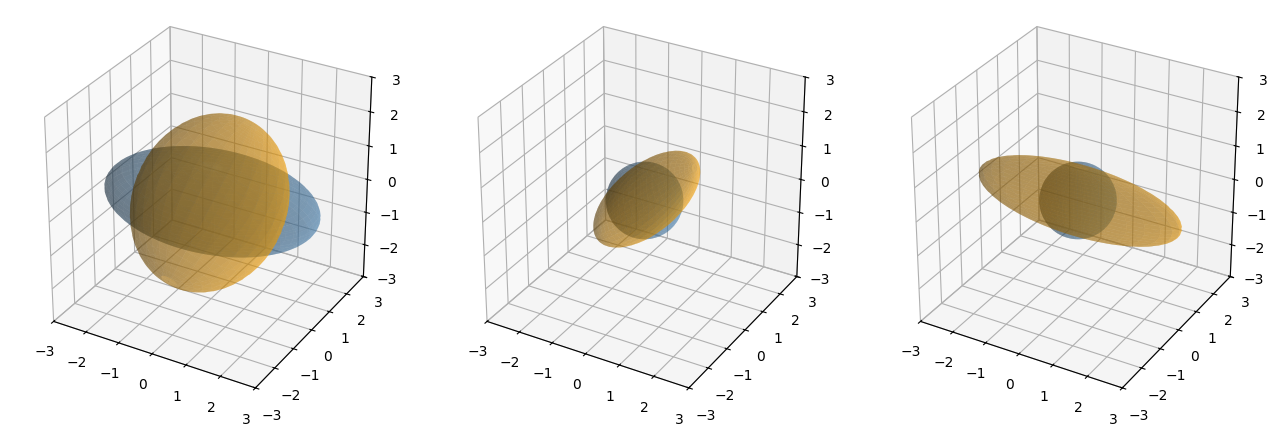

In [3]:
from scipy.spatial.transform import Rotation
def surface(ax,radii,rotation=np.eye(3),color='steelblue'):
    u,v=np.meshgrid(np.linspace(0,2*np.pi,60),np.linspace(0,np.pi,30))
    p=np.array([radii[0]*np.sin(v)*np.cos(u),radii[1]*np.sin(v)*np.sin(u),radii[2]*np.cos(v)])
    p=(rotation@p.reshape(3,-1)).reshape(p.shape)
    ax.plot_surface(*p,color=color,alpha=.4,linewidth=0)
fig=plt.figure(figsize=(13,4),layout='constrained')
for j,(r1,r2,axis,angle) in enumerate([((3,2,1),(1,2,3),[2,-1,1],2*np.pi/3),((1,1,1),(2/3,1,3),[1,1,1],np.pi/3),((1,1,1),(3,2/3,1),[0,0,1],0)]):
    ax=fig.add_subplot(1,3,j+1,projection='3d'); axis=np.array(axis)/np.linalg.norm(axis)
    surface(ax,r1); surface(ax,r2,Rotation.from_rotvec(axis*angle).as_matrix(),'orange')
    ax.set(xlim=(-3,3),ylim=(-3,3),zlim=(-3,3)); ax.set_box_aspect((1,1,1))
plt.show()

## Example 1


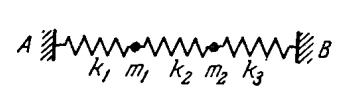


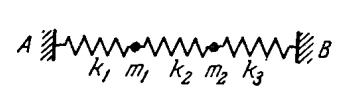

In [4]:
x1,x2,vx1,vx2=sp.symbols('x_1 x_2 v_1 v_2',real=True)
T=m1*vx1**2/2+m2*vx2**2/2; U=k1*x1**2/2+k3*x2**2/2+k2*(x1-x2)**2/2
lgrng31=T-U; enrg31=T+U
kmtrx=sp.hessian(enrg31,(x1,x2)); mmtrx=sp.hessian(enrg31,(vx1,vx2)); display(kmtrx,mmtrx)

Matrix([
[k_1 + k_2,      -k_2],
[     -k_2, k_2 + k_3]])

Matrix([
[m_1,   0],
[  0, m_2]])

In [5]:
eigv3,eigvc3=modes2(mmtrx,kmtrx)
display(eigv3)

[(k_1*m_2 + k_2*m_1 + k_2*m_2 + k_3*m_1 - sqrt(k_1**2*m_2**2 - 2*k_1*k_2*m_1*m_2 + 2*k_1*k_2*m_2**2 - 2*k_1*k_3*m_1*m_2 + k_2**2*m_1**2 + 2*k_2**2*m_1*m_2 + k_2**2*m_2**2 + 2*k_2*k_3*m_1**2 - 2*k_2*k_3*m_1*m_2 + k_3**2*m_1**2))/(2*m_1*m_2),
 (k_1*m_2 + k_2*m_1 + k_2*m_2 + k_3*m_1 + sqrt(k_1**2*m_2**2 - 2*k_1*k_2*m_1*m_2 + 2*k_1*k_2*m_2**2 - 2*k_1*k_3*m_1*m_2 + k_2**2*m_1**2 + 2*k_2**2*m_1*m_2 + k_2**2*m_2**2 + 2*k_2*k_3*m_1**2 - 2*k_2*k_3*m_1*m_2 + k_3**2*m_1**2))/(2*m_1*m_2)]

Normal frequencies and modes for symmetric case (m1=m2, k1=k3):

In [6]:
display([sp.simplify(v.subs({k3:k1,m2:m1})) for v in eigv3])

[k_1/m_1, (k_1 + 2*k_2)/m_1]

In [7]:
display(*[sp.simplify(v.subs({k3:k1,m2:m1})) for v in eigvc3])

Matrix([
[1],
[1]])

Matrix([
[ 1],
[-1]])

## Example 2

Let’s find eigenmodes and frequencies of small plane oscillations  of the double pendulum


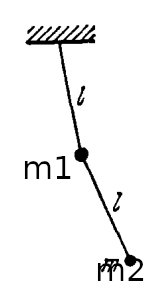


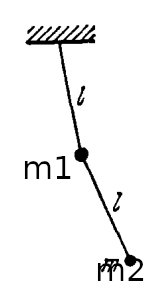

Lagrange function (introducing obvious angle displacements):

$$
L=\frac{{m}_{1}{l}^{2}}{2}{\dot{\varphi }}_{1}^{2}+\frac{{m}_{2}}{2}\left({\dot{x}}^{2}+{\dot{y}}^{2}\right)-{m}_{1}gl\left(1-\cos{{\varphi}_{1}}\right)-{m}_{2} g\left(2l- y\right)\\ x=l\left(\sin{{\varphi }_{1}}+\sin{{\varphi }_{2}}\right), y=l\left(\cos{{\varphi }_{1}}+\cos{{\varphi }_{2}}\right)\\ \dot{x}=l\left({\dot{\varphi }}_{1}\cos{{\varphi }_{1}}+{\dot{\varphi }}_{2}\cos{{\varphi }_{2}}\right), \dot{y}=-l\left({\dot{\varphi }}_{1}\sin{{\varphi }_{1}}+{\dot{\varphi }}_{2}\sin{{\varphi }_{2}}\right)
$$

Lagrange and energy functions:

In [8]:
vx=l*(phid1*sp.cos(phi1)+phid2*sp.cos(phi2)); vy=-l*(phid1*sp.sin(phi1)+phid2*sp.sin(phi2))
T=m1*l*l*phid1**2/2+m2*(vx*vx+vy*vy)/2
U=m1*g*l*(1-sp.cos(phi1))+m2*g*l*(2-sp.cos(phi1)-sp.cos(phi2))
lgrng11=T-U; enrg11=T+U

Series expansion near equilibrium $\left({\varphi }_{1}={\varphi }_{2}=0\right)$:

In [9]:
enrng12=rectangular_series(enrg11,phi1,phi2)
display(enrng12)

g*l*m_1*phi_1**2/2 + g*l*m_2*phi_1**2/2 + g*l*m_2*phi_2**2/2 + l**2*m_1*phidot_1**2/2 + l**2*m_2*phi_1**2*phi_2**2*phidot_1*phidot_2/4 - l**2*m_2*phi_1**2*phidot_1*phidot_2/2 + l**2*m_2*phi_1*phi_2*phidot_1*phidot_2 - l**2*m_2*phi_2**2*phidot_1*phidot_2/2 + l**2*m_2*phidot_1**2/2 + l**2*m_2*phidot_1*phidot_2 + l**2*m_2*phidot_2**2/2

Stiffness matrix:

In [10]:
# Both source matrices include a factor 1/2; it cancels in M^{-1}K.
kmtrx=sp.simplify(sp.hessian(enrng12,(phi1,phi2)).subs({phi1:0,phi2:0,phid1:0,phid2:0})/2)
display(kmtrx)

Matrix([
[g*l*(m_1 + m_2)/2,         0],
[                0, g*l*m_2/2]])

Mass matrix:

In [11]:
mmtrx=sp.simplify(sp.hessian(enrng12,(phid1,phid2)).subs({phi1:0,phi2:0})/2)
display(mmtrx)

Matrix([
[l**2*(m_1 + m_2)/2, l**2*m_2/2],
[        l**2*m_2/2, l**2*m_2/2]])

Eigenvalues :

In [12]:
double_eigenvalues,double_eigenvectors=modes2(mmtrx,kmtrx)
display(double_eigenvalues)

[g*(m_1 - sqrt(m_2)*sqrt(m_1 + m_2) + m_2)/(l*m_1),
 g*(m_1 + sqrt(m_2)*sqrt(m_1 + m_2) + m_2)/(l*m_1)]

Eigenvectors (normal modes):

In [13]:
eigv=double_eigenvectors
display(*eigv)

Matrix([
[                        1],
[sqrt(m_1 + m_2)/sqrt(m_2)]])

Matrix([
[                         1],
[-sqrt(m_1 + m_2)/sqrt(m_2)]])

Orthogonality check:

In [14]:
orthogonality=sp.simplify((eigv[0].T*mmtrx*eigv[1])[0]); display(orthogonality==0); assert orthogonality==0

True

## Example 3

Let’s consider small oscillations of the following system with two eigenmodes


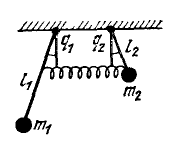


with checking the result in limiting case of infinite rigidity of the spring ($k\to \infty $). Lagrange|energy functions:
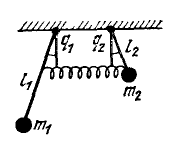

In [15]:
coupling=k*l2**2
T=m1*l1*l1*qd1**2/2+m2*l2*l2*qd2**2/2
U=m1*g*l1*(1-sp.cos(q1))+m2*g*l2*(1-sp.cos(q2))+coupling*(sp.sin(q1)-sp.sin(q2))**2/2
lgrng21=T-U; enrg21=T+U

Expand the energy to second order in each angle (the source’s rectangular Taylor expansion):

In [16]:
enrg22=rectangular_series(enrg21,q1,q2)
display(enrg22)

g*l_1*m_1*q_1**2/2 + g*l_2*m_2*q_2**2/2 + k*l_2**2*q_1**2/2 - k*l_2**2*q_1*q_2 + k*l_2**2*q_2**2/2 + l_1**2*m_1*qdot_1**2/2 + l_2**2*m_2*qdot_2**2/2

In [17]:
kmtrx=sp.simplify(sp.hessian(enrg22,(q1,q2)).subs({q1:0,q2:0,qd1:0,qd2:0}))
mmtrx=sp.simplify(sp.hessian(enrg22,(qd1,qd2)).subs({q1:0,q2:0}))
display(kmtrx,mmtrx)

Matrix([
[g*l_1*m_1 + k*l_2**2,           -k*l_2**2],
[           -k*l_2**2, l_2*(g*m_2 + k*l_2)]])

Matrix([
[l_1**2*m_1,          0],
[         0, l_2**2*m_2]])

In [18]:
eigv2,eigvc2=modes2(mmtrx,kmtrx)

Orthogonality check:

In [19]:
orthogonality=sp.simplify((eigvc2[0].T*mmtrx*eigvc2[1])[0]); display(orthogonality); assert orthogonality==0

0

Checking limiting case:

In [20]:
# At infinite coupling the finite-frequency mode has q1=q2.
finite_limit=g*(l1*m1+l2*m2)/(l1**2*m1+l2**2*m2)
display(finite_limit,sp.oo)

g*(l_1*m_1 + l_2*m_2)/(l_1**2*m_1 + l_2**2*m_2)

oo

## Example 4

Four alternating masses constrained to a unit circle have three oscillatory modes and one zero-frequency mode corresponding to uniform rotation.



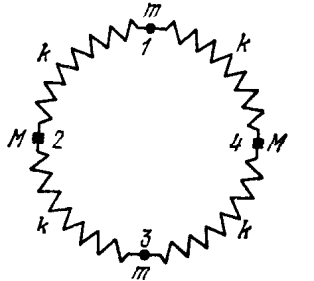


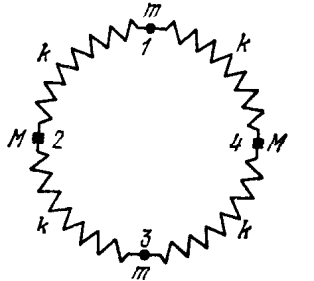

In [21]:
positions=sp.Matrix([phi1,phi2,phi3,phi4]); rates=sp.Matrix([phid1,phid2,phid3,phid4])
enrgring=(m1*(phid1**2+phid3**2)+m2*(phid2**2+phid4**2))/2+k*((phi1-phi2)**2+(phi4-phi3)**2+(phi3-phi2)**2+(phi1-phi4)**2)/2
kmtrx=sp.hessian(enrgring,positions); mmtrx=sp.hessian(enrgring,rates)
display(enrgring,kmtrx,mmtrx)

k*((phi_1 - phi_2)**2 + (phi_1 - phi_4)**2 + (-phi_2 + phi_3)**2 + (-phi_3 + phi_4)**2)/2 + m_1*(phidot_1**2 + phidot_3**2)/2 + m_2*(phidot_2**2 + phidot_4**2)/2

Matrix([
[2*k,  -k,   0,  -k],
[ -k, 2*k,  -k,   0],
[  0,  -k, 2*k,  -k],
[ -k,   0,  -k, 2*k]])

Matrix([
[m_1,   0,   0,   0],
[  0, m_2,   0,   0],
[  0,   0, m_1,   0],
[  0,   0,   0, m_2]])

In [22]:
ring_values=[2*k*(m1+m2)/(m1*m2),2*k/m1,2*k/m2,sp.Integer(0)]
display(ring_values)

[2*k*(m_1 + m_2)/(m_1*m_2), 2*k/m_1, 2*k/m_2, 0]

In [23]:
ring_vectors=[sp.Matrix([1,-m1/m2,1,-m1/m2]),sp.Matrix([1,0,-1,0]),sp.Matrix([0,1,0,-1]),sp.ones(4,1)]
for value,vector in zip(ring_values,ring_vectors): assert sp.simplify(kmtrx*vector-value*mmtrx*vector)==sp.zeros(4,1)
display(*ring_vectors)

Matrix([
[       1],
[-m_1/m_2],
[       1],
[-m_1/m_2]])

Matrix([
[ 1],
[ 0],
[-1],
[ 0]])

Matrix([
[ 0],
[ 1],
[ 0],
[-1]])

Matrix([
[1],
[1],
[1],
[1]])

In [24]:
V=sp.Matrix.hstack(*ring_vectors); display(sp.simplify(V.T*mmtrx*V))

Matrix([
[2*m_1*(m_1 + m_2)/m_2,     0,     0,             0],
[                    0, 2*m_1,     0,             0],
[                    0,     0, 2*m_2,             0],
[                    0,     0,     0, 2*m_1 + 2*m_2]])

## Linear algebra Appendix: Diagonalization and Jordan normal form of linear operator

Over the complex numbers, a matrix with distinct eigenvalues is diagonalizable. In an eigenbasis its action is a collection of one-dimensional scalings, and the vector space decomposes into invariant subspaces:

$$
L = {\oplus }_{i=1}^{n} {L}_{i}\tag{5}
$$

Remind that the vector which define 1-dim invariant subspace:

$$
A \mathbf{v} =\lambda  \mathbf{v}\tag{6}
$$

is an eigenvector with eigenvalue $\lambda$. A direct-sum decomposition into invariant subspaces gives a block-diagonal matrix, with each block describing the action on one subspace:

$$
L = {\oplus }_{i=1}^{m} {L}_{i},{\sum }_{i=1}^{m} dim {L}_{i}=dim L\tag{7}
$$

Over an algebraically closed field such as $\mathbb{C}$ ([Fundamental_theorem_of_algebra](https://en.wikipedia.org/wiki/Fundamental_theorem_of_algebra)), every nontrivial finite-dimensional operator has an eigenvector. Over $\mathbb{R}$, a planar rotation provides a counterexample:

$$
\left(\begin{matrix}\cos{\alpha}  & \sin{\alpha} \\ -\sin{\alpha}  & \cos{\alpha} \end{matrix}\right)
$$

Assume henceforth that the scalar field is algebraically closed. In two dimensions, choosing an eigenvector as the first basis vector gives

$$
\left(\begin{matrix}{\lambda }_{1} & {a}_{12}\\ 0 & {a}_{22}\end{matrix}\right), {a}_{12}\ne 0
$$

If $a_{22}\ne\lambda_1$, a second independent eigenvector exists. If the eigenvalues coincide and the off-diagonal entry is nonzero, rescale the first basis vector to make $a_{12}=1$. This gives the simplest nondiagonalizable example:

$$
\left(\begin{matrix}\lambda  & 1\\ 0 & \lambda \end{matrix}\right)\tag{8}
$$

The eigenvectors do not span the whole space, although $\left(A-\lambda I\right)^2=0$. In three dimensions, two examples are

$$
\left(\begin{matrix}{\lambda }_{1} & 1 & 0\\ 0 & {\lambda }_{1} & 0\\ 0 & 0 & {\lambda }_{2}\end{matrix}\right), \left(\begin{matrix}\lambda  & 1 & 0\\ 0 & \lambda  & 1\\ 0 & 0 & \lambda \end{matrix}\right)
$$

The first matrix splits into a two-dimensional and a one-dimensional invariant summand. The second is a single indecomposable Jordan block. This illustrates the general idea.

To find all eigenvectors in algebraic terms we consider the characteristic equation:

$$
Det\left(A-\lambda I\right)=0={\prod }_{i=1}^{m}{\left(\lambda -{\lambda }_{i}\right)}^{{r}_{i}}, {\sum }_{i=1}^{m}{r}_{i}=n\tag{9}
$$

Here $r_i$ is the algebraic multiplicity of the root $\lambda_i$. First suppose that all roots are simple. Consider the characteristic polynomial evaluated at the operator:

$$
{P}_{\text{char}}\left(A\right)={\prod }_{i=1}^{n}\left(A-{\lambda }_{i}\right)\tag{10}
$$

It is easy to show that (${P}_{\text{char}}$ is annulling A):

$$
{P}_{\text{char}}\left(A\right)\mathbf{v}=0, \forall \mathbf{v}\in L\Rightarrow v = {\sum }_{i=1}^{n}{v}^{i}{\mathbf{e}}_{i}\tag{11}
$$

By the same virtue in case of invariant spaces of different dimensions the annulling operator is obviously (in fact we substitute λ→A in )

$$
{P}_{\text{char}}\left(A\right)={\prod }_{i=1}^{m}{\left(A-{\lambda }_{i}\right)}^{{r}_{i}}\tag{12}
$$

but here all invariant 1-dim eigenspaces do not cover all L. The reason is clear: for each eigenvalue there are associated vectors which form invariant space with dimension >1 (see elementary example above).

A matrix $B$ is nilpotent if $B^k=0$ for some positive integer $k$. The characteristic-polynomial identity above is the Cayley–Hamilton theorem. Generalized eigenvectors generate Jordan chains; an eigenvalue with algebraic multiplicity $r_i$ can have several chains whose lengths sum to $r_i$.

$$
{\left(A-{\lambda }_{i}\right)}^{{r}_{i}}{\mathbf{e}}_{{r}_{i}}=0\tag{13}
$$

it generates the chain-basis:

$$
{\mathbf{e}}_{{r}_{i}}\overset{A-\lambda }{\to }{\mathbf{e}}_{{r}_{i}-1}\overset{A-\lambda }{\to }{\mathbf{e}}_{{r}_{i}-2}\overset{A-\lambda }{\to }...\overset{A-\lambda }{\to }{\mathbf{e}}_{1}\overset{A-\lambda }{\to }0\tag{14}
$$

In each Jordan-chain basis, the restriction of the operator is a Jordan block:

$$
\left(\begin{matrix}\lambda  & 1 & 0 & ... & 0\\ 0 & \lambda  & 1 & ... & 0\\ ... & ... & ... & ... & ...\\ ... & ... & ... & \lambda  & 1\\ 0 & ... & ... & 0 & \lambda \end{matrix}\right)\tag{15}
$$

The Jordan decomposition is the representation of linear operator in terms of such blocks

$$
\left(\begin{matrix}{J}_{{r}_{1}}\left({\lambda }_{1}\right) & ... & 0\\ 0 & ... & ...\\ ... & ... & 0\\ 0 & ... & {J}_{{r}_{m}}\left({\lambda }_{m}\right)\end{matrix}\right)\tag{16}
$$

Thus every complex square matrix has a Jordan form. It is diagonalizable exactly when all its Jordan blocks have size one:

$$
A \to  \exists  C, det C \ne 0 \Rightarrow {C}^{-1} A C - \text{block diagonal}\tag{17}
$$

Powers $A^n$ can then be computed block by block, using the nilpotence of $J-\lambda I$.

### Problems

Find frequency of small oscillations on spherical surface 

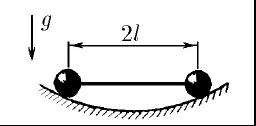


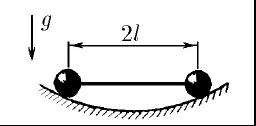

2. Describe how constraints on the coordinates change the normal frequencies.

3. Find the frequencies and normal modes of three identical masses at the vertices of an equilateral triangle.

4. Prove the following identity for a $2\times2$ matrix $M$.

$$
{M}^{1/2}=\frac{M+\sqrt{det M}}{\sqrt{Tr M+2\sqrt{det M}}}
$$

5. A diatomic molecule has angular momentum $L$. Find the resulting shift of its vibrational frequency.

Find ${A}^{n}$ for $A=\left(\begin{matrix}1 & 1\\ -1 & 3\end{matrix}\right)$

Find Jordan representation for $A=\left(\begin{matrix}6 & -8 & 3\\ 1 & 0 & 1\\ 0 & -1 & 3\end{matrix}\right)$  and  compute Exp(A)

8. Compute $J_r\left(\lambda\right)^k$.

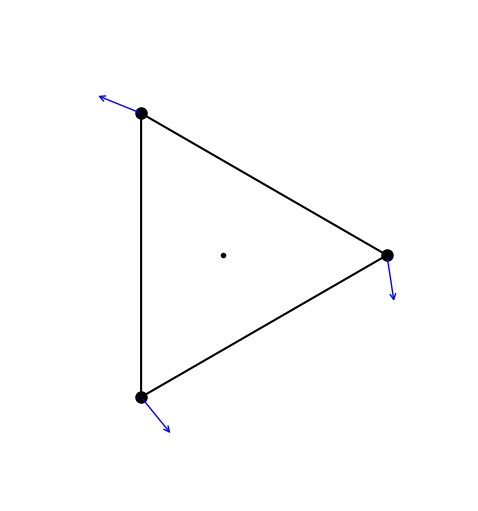

In [25]:
triangle_vertices=np.array([[1,0],[-.5,np.sqrt(3)/2],[-.5,-np.sqrt(3)/2]])
def draw_triangle(ax,vectors):
    closed=np.vstack([triangle_vertices,triangle_vertices[0]])
    ax.plot(*closed.T,'k-'); ax.plot(*triangle_vertices.T,'ko',ms=8); ax.plot(0,0,'ko',ms=3)
    for p,v in zip(triangle_vertices,np.asarray(vectors,dtype=float).reshape(3,2)):
        ax.annotate('',xy=p+.3*v,xytext=p,arrowprops={'arrowstyle':'->','color':'blue'})
    ax.set(xlim=(-1.3,1.5),ylim=(-1.5,1.5),aspect='equal'); ax.axis('off')
rng=np.random.default_rng(42); angles=rng.uniform(0,2*np.pi,3)
fig,ax=plt.subplots(figsize=(5,5),layout='constrained'); draw_triangle(ax,np.column_stack([np.cos(angles),np.sin(angles)])); plt.show()

In [26]:
coordinates=sp.Matrix(sp.symbols('x_1 y_1 x_2 y_2 x_3 y_3',real=True))
vertices=[sp.Matrix([1,0]),sp.Matrix([-sp.Rational(1,2),sp.sqrt(3)/2]),sp.Matrix([-sp.Rational(1,2),-sp.sqrt(3)/2])]
displacements=[coordinates[2*j:2*j+2,0] for j in range(3)]
upot=0
for j,k0 in [(0,1),(1,2),(0,2)]:
    direction=(vertices[j]-vertices[k0])/sp.sqrt(3)
    upot+=(direction.dot(displacements[j]-displacements[k0]))**2/2
stiffness=sp.simplify(sp.hessian(upot,coordinates)); omega2=sp.symbols('omega_squared')
display(sp.solve((omega2*sp.eye(6)-stiffness).det(),omega2))

[0, 3/2, 3]

In [36]:
# The source's coefficient matrix at omega^2=0 is -K.
eigenpairs=sorted((-stiffness).eigenvects(),key=lambda item:float(item[0]))
triangle_values=[]; triangle_modes=[]
for value,multiplicity,vectors in eigenpairs:
    for vector in vectors: triangle_values.append(value); triangle_modes.append(vector)
# Match the original normalization of the nondegenerate breathing mode.
eig0=sp.Matrix.vstack(*vertices); triangle_modes[0]=-2*eig0/sp.sqrt(3)
display(triangle_values,triangle_modes[0],eig0)

[-3, -3/2, -3/2, 0, 0, 0]

Matrix([
[-2*sqrt(3)/3],
[           0],
[   sqrt(3)/3],
[          -1],
[   sqrt(3)/3],
[           1]])

Matrix([
[         1],
[         0],
[      -1/2],
[ sqrt(3)/2],
[      -1/2],
[-sqrt(3)/2]])

In [28]:
display((3*sp.eye(6)-stiffness)*eig0,sp.simplify((3*sp.eye(6)-stiffness)*triangle_modes[0]))

Matrix([
[0],
[0],
[0],
[0],
[0],
[0]])

Matrix([
[0],
[0],
[0],
[0],
[0],
[0]])

In [29]:
display(triangle_modes[0][2:4,0])

Matrix([
[-sqrt(3)/3],
[         1]])

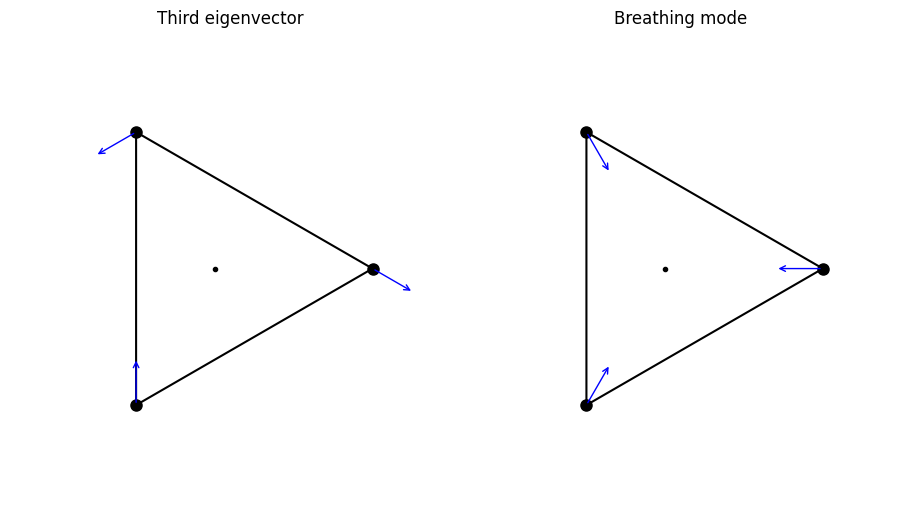

In [30]:
fig,axes=plt.subplots(1,2,figsize=(9,5),layout='constrained')
draw_triangle(axes[0],triangle_modes[2]); axes[0].set_title('Third eigenvector')
draw_triangle(axes[1],eig0); axes[1].set_title('Breathing mode'); plt.show()

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)